# K-Means Clustering from Scratch – Assignment Notebook
Each task is given as a question cell followed directly by its answer cells.

**File created alongside this notebook:** `zomato_restaurants_dataset.csv` (600 rows, used in Task 5)

In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

**1.**  
Given a small dataset of 2D points representing food delivery locations (e.g., [2,3], [5,8], [1,2], [6,9], [7,7]), plot the points on graph paper or using matplotlib, randomly pick two initial centroids, and manually assign each point to the nearest centroid using Euclidean distance.

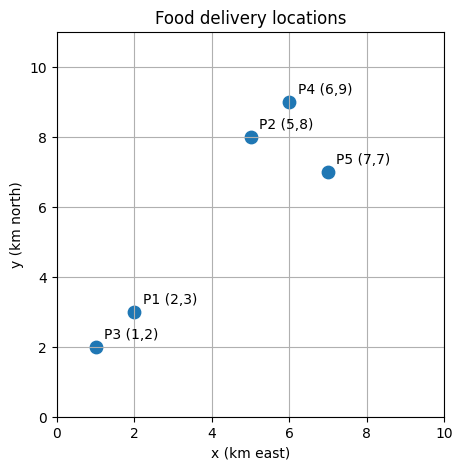

In [2]:
points = [[2, 3], [5, 8], [1, 2], [6, 9], [7, 7]]

# Plot the delivery locations
plt.figure(figsize=(5, 5))
for i, (x, y) in enumerate(points):
    plt.scatter(x, y, c="tab:blue", s=80)
    plt.annotate(f"P{i+1} ({x},{y})", (x, y), textcoords="offset points", xytext=(6, 6))
plt.xlabel("x (km east)"); plt.ylabel("y (km north)")
plt.title("Food delivery locations"); plt.grid(True); plt.xlim(0, 10); plt.ylim(0, 11); plt.show()

In [3]:
# Randomly pick two of the points as initial centroids (seed fixed so the result is repeatable)
random.seed(1)
c1, c2 = random.sample(points, 2)
print("Initial centroids -> C1 =", c1, " C2 =", c2)

# Manual Euclidean distance: sqrt((x1-x2)^2 + (y1-y2)^2)
def euclid(p, q):
    return ((p[0] - q[0]) ** 2 + (p[1] - q[1]) ** 2) ** 0.5

rows = []
for i, p in enumerate(points):
    d1, d2 = euclid(p, c1), euclid(p, c2)
    rows.append({"Point": f"P{i+1} {p}", "Dist to C1": round(d1, 2), "Dist to C2": round(d2, 2),
                 "Assigned to": "C1" if d1 <= d2 else "C2"})
table = pd.DataFrame(rows)
table

Initial centroids -> C1 = [5, 8]  C2 = [2, 3]


,Point,Dist to C1,Dist to C2,Assigned to
0,"P1 [2, 3]",5.83,0.00,C2
1,"P2 [5, 8]",0.00,5.83,C1
2,"P3 [1, 2]",7.21,1.41,C2
3,"P4 [6, 9]",1.41,7.21,C1
4,"P5 [7, 7]",2.24,6.40,C1


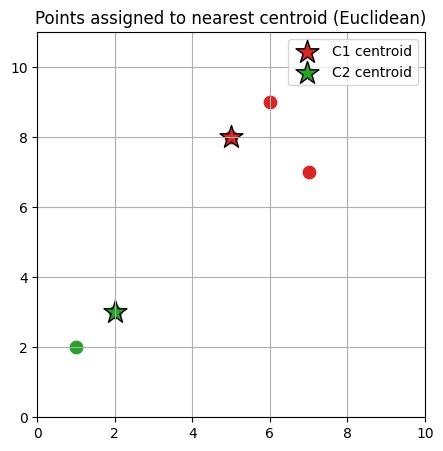

In [4]:
# Plot the result: colour = assigned centroid, star = centroid
colors = {"C1": "tab:red", "C2": "tab:green"}
plt.figure(figsize=(5, 5))
for p, a in zip(points, table["Assigned to"]):
    plt.scatter(*p, c=colors[a], s=80)
plt.scatter(*c1, c="tab:red", marker="*", s=300, edgecolor="k", label="C1 centroid")
plt.scatter(*c2, c="tab:green", marker="*", s=300, edgecolor="k", label="C2 centroid")
plt.title("Points assigned to nearest centroid (Euclidean)"); plt.legend(); plt.grid(True)
plt.xlim(0, 10); plt.ylim(0, 11); plt.show()

**Working (example for one point):** if P1 = (2,3) and a centroid is at (1,2), distance = √((2−1)² + (3−2)²) = √2 ≈ 1.41. Each point is compared with both centroids and goes to the smaller distance, as shown in the table above.

**2.**  
Write a Python function assign_clusters(points, centroids) that takes a list of points and a list of centroids, and returns a list showing which cluster each point belongs to using Euclidean distance.

In [5]:
import math

def assign_clusters(points, centroids):
    """Return a list: index of the nearest centroid (Euclidean) for every point."""
    assignments = []
    for p in points:
        distances = [math.sqrt(sum((a - b) ** 2 for a, b in zip(p, c))) for c in centroids]
        assignments.append(distances.index(min(distances)))
    return assignments

# Test with the Task 1 data
centroids = [c1, c2]
print("Points   :", points)
print("Centroids:", centroids)
print("Clusters :", assign_clusters(points, centroids))

Points   : [[2, 3], [5, 8], [1, 2], [6, 9], [7, 7]]
Centroids: [[5, 8], [2, 3]]
Clusters : [1, 0, 1, 0, 0]


**3.**  
Update your assign_clusters code to work with Manhattan distance as well. Allow the user to choose between 'euclidean' and 'manhattan' as a parameter.

In [7]:
def assign_clusters(points, centroids, metric="euclidean"):
    """Return the nearest-centroid index for each point.
    metric: 'euclidean' (default) or 'manhattan'."""
    metric = metric.lower()
    if metric == "euclidean":
        dist = lambda p, c: math.sqrt(sum((a - b) ** 2 for a, b in zip(p, c)))
    elif metric == "manhattan":
        dist = lambda p, c: sum(abs(a - b) for a, b in zip(p, c))
    else:
        raise ValueError("metric must be 'euclidean' or 'manhattan'")
    assignments = []
    for p in points:
        d = [dist(p, c) for c in centroids]
        assignments.append(d.index(min(d)))
    return assignments

pts = [[2, 3], [5, 8], [1, 2], [6, 9], [7, 7], [4, 4]]
cents = [[1, 1], [6, 8]]
print("Euclidean:", assign_clusters(pts, cents, "euclidean"))
print("Manhattan:", assign_clusters(pts, cents, "manhattan"))

# A case where the two metrics can disagree
p_test, c_test = [[0, 0]], [[3, 3], [5, 0]]       # Euclid: 4.24 vs 5.0 -> cluster 0 ; Manhattan: 6 vs 5 -> cluster 1
print("Edge case Euclidean:", assign_clusters(p_test, c_test, "euclidean"),
      "| Manhattan:", assign_clusters(p_test, c_test, "manhattan"))
try:
    assign_clusters(pts, cents, "cosine")
except ValueError as e:
    print("Invalid metric ->", e)

Euclidean: [0, 1, 0, 1, 1, 0]
Manhattan: [0, 1, 0, 1, 1, 0]
Edge case Euclidean: [0] | Manhattan: [1]
Invalid metric -> metric must be 'euclidean' or 'manhattan'


**4.**  
Implement a function update_centroids(points, assignments, k) that calculates the new centroid for each cluster as the mean of the assigned points. Test it with a sample dataset of your choice.

In [8]:
def update_centroids(points, assignments, k):
    """New centroid of each cluster = mean of the points assigned to it.
    If a cluster has no points, None is returned for it."""
    new_centroids = []
    for cluster_id in range(k):
        members = [p for p, a in zip(points, assignments) if a == cluster_id]
        if members:
            dims = len(members[0])
            new_centroids.append([round(sum(m[d] for m in members) / len(members), 2) for d in range(dims)])
        else:
            new_centroids.append(None)
    return new_centroids

# Sample dataset: 8 customer locations in 2 areas
sample = [[1, 1], [2, 1], [1, 2], [2, 2], [8, 8], [9, 8], [8, 9], [9, 9]]
start = [[1, 1], [9, 9]]

a = assign_clusters(sample, start)
print("Assignments:", a)
print("New centroids:", update_centroids(sample, a, k=2))   # expect [1.5, 1.5] and [8.5, 8.5]

Assignments: [0, 0, 0, 0, 1, 1, 1, 1]
New centroids: [[1.5, 1.5], [8.5, 8.5]]


In [9]:
# Bonus: repeat assign -> update until centroids stop moving (this is K-Means itself)
cents = [[1, 1], [2, 1]]                      # deliberately poor start
for it in range(1, 6):
    a = assign_clusters(sample, cents)
    new = update_centroids(sample, a, k=2)
    print(f"Iteration {it}: assignments={a}, centroids={new}")
    if new == cents:
        print("Converged."); break
    cents = new

Iteration 1: assignments=[0, 1, 0, 1, 1, 1, 1, 1], centroids=[[1.0, 1.5], [6.33, 6.17]]
Iteration 2: assignments=[0, 0, 0, 0, 1, 1, 1, 1], centroids=[[1.5, 1.5], [8.5, 8.5]]
Iteration 3: assignments=[0, 0, 0, 0, 1, 1, 1, 1], centroids=[[1.5, 1.5], [8.5, 8.5]]
Converged.


**5.**  
Use the Elbow Method to determine the optimal number of clusters (k) for a dataset of your choice (e.g., favorite songs by tempo and danceability, or Zomato restaurant ratings and price). Plot the within-cluster sum of squares for k=1 to k=6 and identify the 'elbow' point.

*Hint: Use sklearn's KMeans and matplotlib for plotting.*

(600, 3)


,restaurant_id,avg_cost_for_two,rating
0,1,250,3.3
1,2,280,3.5
2,3,290,3.2
3,4,310,3.2
4,5,1630,4.7


,restaurant_id,avg_cost_for_two,rating
count,600.00,600.00,600.00
mean,300.50,845.42,3.78
std,173.35,527.92,0.71
min,1.00,160.00,2.40
25%,150.75,297.50,3.10
50%,300.50,710.00,3.50
75%,450.25,1080.00,4.50
max,600.00,1940.00,4.90


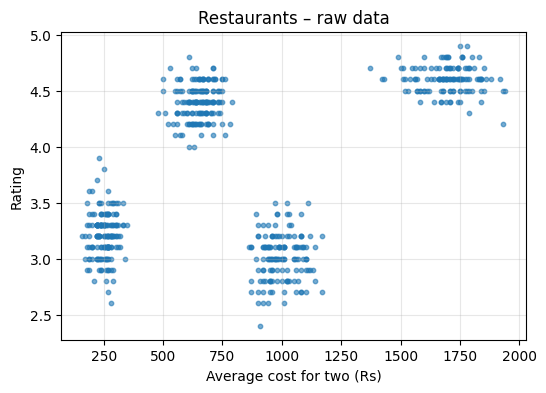

In [10]:
# Dataset: 600 Zomato-style restaurants (average cost for two in Rs, rating out of 5)
zomato = pd.read_csv("zomato_restaurants_dataset.csv")
print(zomato.shape)
display(zomato.head())
display(zomato.describe().round(2))

plt.figure(figsize=(6, 4))
plt.scatter(zomato["avg_cost_for_two"], zomato["rating"], s=10, alpha=.6)
plt.xlabel("Average cost for two (Rs)"); plt.ylabel("Rating"); plt.title("Restaurants – raw data"); plt.grid(alpha=.3); plt.show()

In [11]:
# Scale features so cost (hundreds) does not dominate rating (1-5)
X = zomato[["avg_cost_for_two", "rating"]].values
X_scaled = (X - X.mean(axis=0)) / X.std(axis=0)

ks = range(1, 7)
wcss = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    wcss.append(km.inertia_)                     # within-cluster sum of squares

pd.DataFrame({"k": list(ks), "WCSS": np.round(wcss, 1)})

,k,WCSS
0,1,1200.0
1,2,495.6
2,3,205.8
3,4,47.3
4,5,39.4
5,6,34.0


 k  WCSS drop vs k-1 (%)
 2                  58.7
 3                  58.5
 4                  77.0
 5                  16.7
 6                  13.6

Elbow point: k = 4


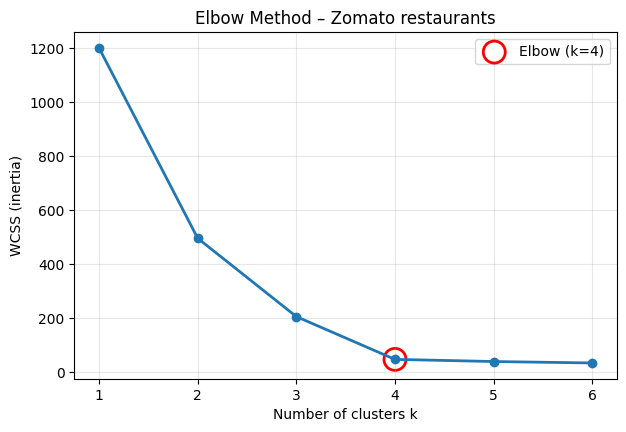

In [12]:
# Reading the elbow: % reduction in WCSS gained by each extra cluster
wcss_arr = np.array(wcss)
gain = (1 - wcss_arr[1:] / wcss_arr[:-1]) * 100
print(pd.DataFrame({"k": list(range(2, 7)), "WCSS drop vs k-1 (%)": gain.round(1)}).to_string(index=False))

# Elbow = last k whose extra cluster still cuts WCSS by more than 30%; after that the gains flatten
elbow_k = max(k for k, g in zip(range(2, 7), gain) if g > 30)
print("\nElbow point: k =", elbow_k)

plt.figure(figsize=(7, 4.5))
plt.plot(list(ks), wcss, "o-", lw=2)
plt.scatter([elbow_k], [wcss[elbow_k - 1]], s=250, facecolors="none", edgecolors="red", linewidths=2, label=f"Elbow (k={elbow_k})")
plt.xlabel("Number of clusters k"); plt.ylabel("WCSS (inertia)"); plt.title("Elbow Method – Zomato restaurants")
plt.xticks(list(ks)); plt.grid(alpha=.3); plt.legend(); plt.show()

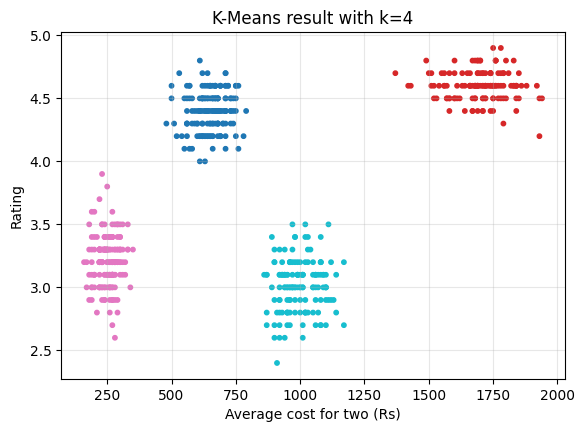

,restaurants,avg_cost,avg_rating
cluster,,,
0,160,650.4,4.4
1,130,1699.0,4.6
2,170,251.5,3.2
3,140,996.8,3.0


In [13]:
# Verify: cluster with the chosen k and describe the groups
final = KMeans(n_clusters=elbow_k, n_init=10, random_state=42).fit(X_scaled)
zomato["cluster"] = final.labels_

plt.figure(figsize=(6.5, 4.5))
plt.scatter(zomato["avg_cost_for_two"], zomato["rating"], c=zomato["cluster"], cmap="tab10", s=10)
plt.xlabel("Average cost for two (Rs)"); plt.ylabel("Rating"); plt.title(f"K-Means result with k={elbow_k}"); plt.grid(alpha=.3); plt.show()

zomato.groupby("cluster").agg(restaurants=("restaurant_id", "count"),
                              avg_cost=("avg_cost_for_two", "mean"),
                              avg_rating=("rating", "mean")).round(1)

**Conclusion:** WCSS falls steeply from k=1 to k=4 (the 4th cluster alone cuts it by about 77%) and then flattens (k=5 gives only about 17%), so more clusters add little benefit. The elbow is at **k = 4**, which matches four sensible restaurant groups: budget/street food, popular mid-range, overpriced mid-range, and premium fine dining (see the cluster table above).